# Longitudinal infant gut microbiome: Beta diversity

**Goal:** This notebook investigates infant-specific differences in microbial community composition using Bray-Curtis dissimilarities.


1. Within- and between-infant comparisons across ten age pairs.
2. One-sided permutation tests with Holm correction to assess infant-specific similarity.
3. Longitudinal mixed-effects models examining associations with age, delivery mode and infant sex.


**Note:** Sections with titles in parentheses contain exploratory analyses. Their results are not included in the final report or presentation.


## 0. Setup

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import qiime2 as q2
import matplotlib.pyplot as plt
import seaborn as sns
from skbio import DistanceMatrix

%matplotlib inline

# project directories
project_dir = Path("/home/jovyan/MicroOdyssey_clean")
metadata_dir = project_dir / "data"
diversity_dir = project_dir / "output" / "04_diversityanalyses"

# figures
fig_dir = diversity_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# plot settings
sns.set_theme(style="whitegrid", context="talk")

AGES = [0, 2, 6, 12, 24]
AGE_LABELS = ["Birth", "2 months", "6 months", "12 months", "24 months"]
AGE_PALETTE = sns.color_palette("mako", len(AGES))
COMP_COLORS = {"Same infant": "#4A9D9D", "Different infants": "#53649A"}
DARK = "#17253A"

# save figures
def save_fig(name):
    plt.savefig(fig_dir / name, dpi=300, bbox_inches="tight")

## 1. Load data

In [6]:
# Sample metadata
meta = pd.read_csv(metadata_dir / "metadata.tsv", sep="\t", index_col=0)

print("Sample with metadata:", len(meta))

Sample with metadata: 234


## 2. Beta diversity: same infant vs. different infants

### 2.1 Import QIIME 2 Bray-Curtis distance matrix

The precomputed Bray-Curtis distance matrix is imported
from QIIME 2 and converted into a pandas DataFrame
for downstream pairwise comparisons.

In [7]:
bray = q2.Artifact.load(diversity_dir /"core-metrics-results"/ "bray_curtis_distance_matrix.qza").view(DistanceMatrix).to_data_frame()

print("Bray-Curtis distance matrix:", bray.shape)
display(bray.head())

Bray-Curtis distance matrix: (228, 228)


,SRR25052449,SRR25052450,SRR25052451,SRR25052452,SRR25052453,SRR25052454,SRR25052455,SRR25052456,SRR25052458,SRR25052459,...,SRR25052710,SRR25052711,SRR25052712,SRR25052713,SRR25052714,SRR25052715,SRR25052716,SRR25052717,SRR25052719,SRR25052720
SRR25052449,0.000000,0.707676,0.635544,0.785957,0.937138,0.562068,0.742996,0.709167,0.532372,0.563191,...,0.587871,0.473906,0.552430,0.756723,0.833954,0.930196,0.428782,0.663079,0.835837,0.938275
SRR25052450,0.707676,0.000000,0.832670,0.716435,0.509850,0.789048,0.618839,0.591820,0.758640,0.746987,...,0.745047,0.791604,0.796786,0.800197,0.872061,0.508621,0.676249,0.825243,0.477714,0.517317
SRR25052451,0.635544,0.832670,0.000000,0.462546,0.950608,0.793317,0.839843,0.848261,0.801690,0.821659,...,0.824923,0.692433,0.596993,0.773844,0.731208,0.943120,0.666588,0.799421,0.873559,0.950071
SRR25052452,0.785957,0.716435,0.462546,0.000000,0.827685,0.844688,0.749017,0.757969,0.855349,0.877815,...,0.853362,0.794350,0.742740,0.707104,0.870415,0.825181,0.702748,0.853644,0.752827,0.828535
SRR25052453,0.937138,0.509850,0.950608,0.827685,0.000000,0.957147,0.718862,0.686114,0.961439,0.960372,...,0.961360,0.961300,0.943627,0.865133,0.954073,0.044638,0.872877,0.953538,0.546580,0.051201


### 2.2 Build a table of sample pairs

Distinct sample pairs were obtained from the Bray-Curtis distance matrix and grouped by infant identity and sampling ages.

Since samples appear in multiple pairs, pairwise distances are not independent. To account for this, descriptive comparisons were complemented by permutation tests, as mentioned in Section 2.3.1.


In [8]:
# keep samples that are in the distance matrix and have complete metadata
info = meta.loc[bray.index.intersection(meta.index), ["host_id", "age_months"]].dropna()
D = bray.loc[info.index, info.index].to_numpy()

# all unique sample pairs (upper triangle)
i, j = np.triu_indices(len(info), k=1)
host = info["host_id"].to_numpy()
age = info["age_months"].to_numpy().astype(int)

pairs_all = pd.DataFrame({
    "Sample1": info.index[i], "Sample2": info.index[j],
    "Same_infant": host[i] == host[j],
    "Age1": np.minimum(age[i], age[j]),     # younger sample of the pair
    "Age2": np.maximum(age[i], age[j]),     # older sample of the pair
    "Bray_Curtis": D[i, j],
})
pairs_all["Age_gap"] = pairs_all["Age2"] - pairs_all["Age1"]
pairs_all["Age_pair"] = pairs_all["Age1"].astype(str) + "–" + pairs_all["Age2"].astype(str)
pairs_all["Comparison"] = np.where(pairs_all["Same_infant"], "Same infant", "Different infants")

# Keep only pairs from different sampling ages
pairs = pairs_all[pairs_all["Age_gap"] > 0].copy()

# compare Bray–Curtis distances
print(f"{len(pairs_all):,} pairs in total; {len(pairs):,} at different ages")
display(pairs.groupby("Comparison")["Bray_Curtis"].describe().round(3))

25,878 pairs in total; 20,381 at different ages


,count,mean,std,min,25%,50%,75%,max
Comparison,,,,,,,,
Different infants,20010.0,0.785,0.154,0.062,0.715,0.831,0.898,0.968
Same infant,371.0,0.740,0.181,0.110,0.636,0.783,0.880,0.965


### 2.3 Within- and between-infant comparisons by age pair

Bray–Curtis dissimilarities are compared among all ten age pairs. For each pair, the difference between median between-infant and within-infant dissimilarities is calculated:

Δ = median(between) − median(within)

A positive difference means greater similarity within infants.


#### 2.3.1 One-sided permutation test

For each age pair, the analysis was restricted to infants with samples available at both time points. Infant matches at one age are randomly permuted 9'999 times to assess whether within-infant dissimilarities are lower than between-infant dissimilarities.

P-values are adjusted across the ten comparisons using the Holm correction.


In [9]:
from itertools import combinations
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(42)
n_perm = 9999 # repeat 9999 times
results = []


# Analyse all ten age pairs
for a, b in combinations(AGES, 2):
    m1 = info[info["age_months"] == a].sort_values("host_id")
    m2 = info[info["age_months"] == b].sort_values("host_id")

    # Keep only infants sampled at both ages
    common = set(m1["host_id"]) & set(m2["host_id"])
    m1 = m1[m1["host_id"].isin(common)]
    m2 = m2[m2["host_id"].isin(common)]

    D_pair = bray.loc[m1.index, m2.index].to_numpy()
    n = len(common)
    same = np.eye(n, dtype=bool)

    # Calculate observed median difference
    within = np.median(D_pair[same])
    between = np.median(D_pair[~same])
    observed = between - within

    # Random infant matching
    null = np.empty(n_perm)
    for i in range(n_perm):
        mask = same[:, rng.permutation(n)]
        null[i] = np.median(D_pair[~mask]) - np.median(D_pair[mask])
    # One-sided permutation p-value
    p = (1 + np.sum(null >= observed)) / (n_perm + 1)
    results.append([f"{a}–{b}", n, within, between, observed, p])

perm_results = pd.DataFrame(results, columns=[
    "Age pair", "Infants", "Within median",
    "Between median", "Difference", "p-value"
])

# Holm correction
perm_results["Adjusted p-value"] = multipletests(
    perm_results["p-value"], method="holm"
)[1]

display(perm_results.round(4))

,Age pair,Infants,Within median,Between median,Difference,p-value,Adjusted p-value
0,0–2,20,0.9099,0.9281,0.0182,0.0693,0.3342
1,0–6,19,0.9315,0.9236,-0.0079,0.5901,0.5901
2,0–12,18,0.9066,0.9256,0.0189,0.0557,0.3342
3,0–24,20,0.9098,0.9286,0.0188,0.0601,0.3342
4,2–6,51,0.6359,0.7926,0.1567,0.0003,0.0030
5,2–12,48,0.8051,0.8419,0.0369,0.0149,0.1043
6,2–24,50,0.8498,0.8599,0.0101,0.1138,0.3342
7,6–12,48,0.7075,0.7721,0.0646,0.0013,0.0117
8,6–24,50,0.7854,0.8061,0.0207,0.0676,0.3342
9,12–24,47,0.6754,0.7495,0.0741,0.0028,0.0224


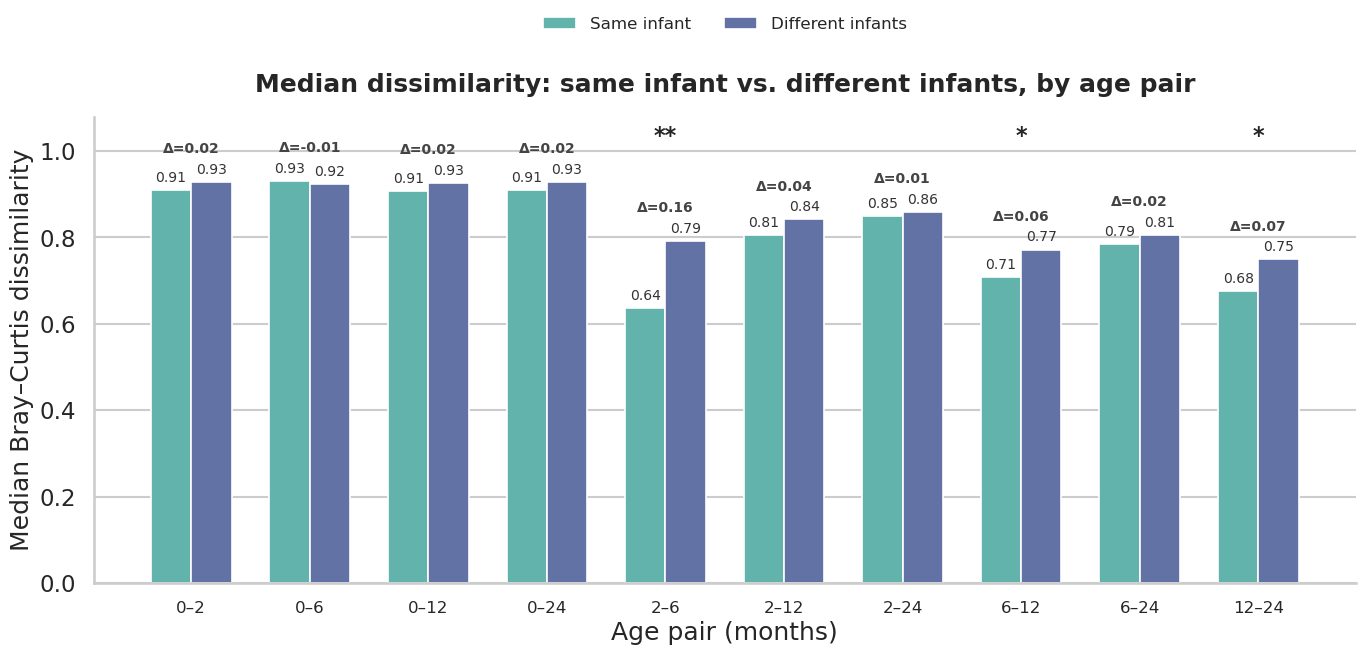

In [11]:
age_labels = perm_results["Age pair"].tolist()
same_vals = perm_results["Within median"].to_numpy()
diff_vals = perm_results["Between median"].to_numpy()
delta = diff_vals - same_vals

x = np.arange(len(age_labels))
width = 0.34

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width/2, same_vals, width, label="Same infant", color="#63B3AD", edgecolor="white", linewidth=1.2)
bars2 = ax.bar(x + width/2, diff_vals, width, label="Different infants", color="#6272A4", edgecolor="white", linewidth=1.2)

# Add median values above bars
for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f"{h:.2f}",
            ha="center", va="bottom", fontsize=10, color="#333333")

# Add median differences
for k, d in enumerate(delta):
    ax.text(x[k], max(same_vals[k], diff_vals[k]) + 0.06, f"Δ={d:.2f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="#444444")

ax.set_xticks(x)

# Add significance stars from holm-adjusted permutation tests
for k, p in enumerate(perm_results["Adjusted p-value"]):
    stars = "**" if p < 0.01 else "*" if p < 0.05 else ""
    if stars:
        ax.text(x[k], 1.02, stars, ha="center",
                fontsize=16, fontweight="bold")
        
ax.set_xticklabels(age_labels, fontsize=12)
ax.set_xlabel("Age pair (months)")
ax.set_ylabel("Median Bray–Curtis dissimilarity")
ax.set_title("Median dissimilarity: same infant vs. different infants, by age pair", fontsize=18, fontweight="bold", pad=18)
ax.set_ylim(0, 1.08)
ax.legend(frameon=False,fontsize=12,loc="lower center",bbox_to_anchor=(0.5, 1.15),ncol=2)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("bray_curtis_exact_age_pairs.png")
plt.show()

### (Overall comparison: same vs. different infants)

Exploratory comparison of Bray-Curtis dissimilarities across all different-age sample pairs. Results are descriptive, as the age-pair distributions differ between groups and sample pairs are not independent.


In [ ]:
order = ["Same infant", "Different infants"]

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=pairs, x="Comparison", y="Bray_Curtis", order=order,
    hue="Comparison", palette=COMP_COLORS, legend=False,
    width=0.48, linewidth=1.5, showfliers=False,
    medianprops={"color": DARK, "linewidth": 2.5}, ax=ax,
)

medians = pairs.groupby("Comparison")["Bray_Curtis"].median()
for k, grp in enumerate(order):
    ax.text(k, medians[grp] + 0.045, f"Median: {medians[grp]:.2f}",
            ha="center", fontsize=12, fontweight="bold", color=DARK)

ax.set_title("Microbial community dissimilarity within vs. between infants", fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("")
ax.set_ylabel("Bray–Curtis dissimilarity")
ax.set_ylim(0, 1.05)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("bray_curtis_same_vs_different_infant.png")
plt.show()

### (Comparison by age gap)

Exploratory comparison of within- and between-infant Bray-Curtis dissimilarities grouped by the time interval between samples. Only age gaps represented in both groups are retained.

In [ ]:
gap_counts = pd.crosstab(pairs["Age_gap"], pairs["Comparison"])
valid_gaps = gap_counts.index[(gap_counts["Same infant"] > 0) & (gap_counts["Different infants"] > 0)]
pairs_matched = pairs[pairs["Age_gap"].isin(valid_gaps)].copy()

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=pairs_matched, x="Age_gap", y="Bray_Curtis",
    hue="Comparison", hue_order=order, palette=COMP_COLORS,
    showfliers=False, width=0.7, ax=ax,
)
ax.set_title("Microbial dissimilarity by infant identity and age gap", fontsize=16, fontweight="bold")
ax.set_xlabel("Age difference between samples (months)")
ax.set_ylabel("Bray–Curtis dissimilarity")
ax.legend(title="", frameon=False, fontsize=11)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
save_fig("bray_curtis_age_matched.png")
plt.show()

### (Separating the two sources of variation)

Exploratory visualisations

Two views: how different are infants *from each other at the same age*, and how much does a *single infant* change across each age interval. 

In [ ]:
between = pairs_all[(~pairs_all["Same_infant"]) & (pairs_all["Age_gap"] == 0)].copy()   # different infants, same age
within = pairs_all[pairs_all["Same_infant"] & (pairs_all["Age_gap"] > 0)].copy()        # same infant, different ages
within["Interval"] = within["Age_pair"]

interval_order = sorted(within["Interval"].unique(),key=lambda s: tuple(map(int, s.split("–"))))

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=between, x="Age1", y="Bray_Curtis", color=COMP_COLORS["Different infants"], showfliers=False, ax=ax)
ax.set_title("Between-infant microbial differences by age")
ax.set_xlabel("Infant age (months)")
ax.set_ylabel("Bray–Curtis dissimilarity")
sns.despine(); plt.tight_layout()
save_fig("between_infants_by_age.png")
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=within, x="Interval", y="Bray_Curtis", order=interval_order,
            color=COMP_COLORS["Same infant"], showfliers=False, ax=ax)
ax.set_title("Within-infant microbial changes across age intervals")
ax.set_xlabel("Age interval (months)")
ax.set_ylabel("Bray–Curtis dissimilarity")
ax.tick_params(axis="x", rotation=45)
sns.despine(); plt.tight_layout()
save_fig("within_infant_by_interval.png")
plt.show()

### (Variance explained by age and infant identity)

Exploratory analysis estimating the proportion of Bray–Curtis variation associated with age and infant identity separately, using a distance-based R² measure.

Adjusted R² values are also computed to account for differences in the number of groups.

**Caution:** Since age and infant identity were analyzed separately, the estimated proportions do not represent their independent contributions. The results should be interpreted descriptively.


In [17]:
def variance_explained(D, groups):
    """R² = 1 - SS_within / SS_total for a distance matrix D and a grouping vector."""
    groups = np.asarray(groups)
    n = len(groups)
    ss_total = (D ** 2).sum() / (2 * n)
    ss_within = 0.0
    for g in np.unique(groups):
        idx = np.where(groups == g)[0]
        ss_within += (D[np.ix_(idx, idx)] ** 2).sum() / (2 * len(idx))
    return 1 - ss_within / ss_total

def adjusted_r2(r2, n, g):
    return 1 - (1 - r2) * (n - 1) / (n - g)

n = len(info)
rows = []
for label, col in [("Age", "age_months"), ("Infant (host_id)", "host_id")]:
    r2 = variance_explained(D, info[col])
    g = info[col].nunique()
    rows.append({"Factor": label, "Groups": g, "R²": r2, "Adjusted R²": adjusted_r2(r2, n, g)})

variance_table = pd.DataFrame(rows).set_index("Factor")
display(variance_table.round(3))

,Groups,R²,Adjusted R²
Factor,,,
Age,5,0.151,0.136
Infant (host_id),55,0.288,0.066


## 3. Effects of delivery mode and infant sex

We investigate whether delivery mode and infant sex are associated with changes in microbial community composition over time, using linear mixed-effects models that account for repeated measurements from the same infant.

Bray–Curtis first distances, calculated relative to each infant's first available sample, are used as the response variable.

**Model 1 — Full model**

Includes age, delivery mode, infant sex and their interactions:

`Distance ~ age_months * delivery_mode * host_sex`

**Model 2 — Simplified model**

Includes the same main effects without interactions:

`Distance ~ age_months + delivery_mode + host_sex`

Both models include an infant-specific random intercept to account for repeated measurements.


In [27]:
#calculate bray-curtis distances
!qiime longitudinal first-distances \
    --i-distance-matrix $diversity_dir/core-metrics-results/bray_curtis_distance_matrix.qza \
    --m-metadata-file $metadata_dir/metadata.tsv \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --o-first-distances $diversity_dir/bray_curtis_first_distances.qza

Saved SampleData[FirstDifferences] to: /home/jovyan/MicroOdyssey_clean/output/04_diversityanalyses/bray_curtis_first_distances.qza


### 3.1 Model 1 – full model

In [34]:
!qiime diversity core-metrics --help

Usage: qiime diversity core-metrics [OPTIONS]

  Applies a collection of diversity metrics (non-phylogenetic) to a feature
  table.

Inputs:
  --i-table ARTIFACT FeatureTable[Frequency]
                          The feature table containing the samples over which
                          diversity metrics should be computed.     [required]
Parameters:
  --p-sampling-depth INTEGER
    Range(1, None)        The total frequency that each sample should be
                          rarefied to prior to computing diversity metrics.
                                                                    [required]
  --m-metadata-file METADATA...
    (multiple arguments   The sample metadata to use in the emperor plots.
     will be merged)                                                [required]
  --p-with-replacement / --p-no-with-replacement
                          Rarefy with replacement by sampling from the
                          multinomial distribution instead of rarefying
          

In [29]:
!qiime longitudinal linear-mixed-effects \
    --m-metadata-file $metadata_dir/metadata.tsv \
    --m-metadata-file $diversity_dir/bray_curtis_first_distances.qza \
    --p-metric Distance \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --p-group-columns delivery_mode,host_sex \
    --p-formula 'Distance ~ age_months * delivery_mode * host_sex' \
    --o-visualization $diversity_dir/bray_curtis_LME_full.qzv

Saved Visualization to: /home/jovyan/MicroOdyssey_clean/output/04_diversityanalyses/bray_curtis_LME_full.qzv


In [30]:
q2.Visualization.load(diversity_dir / "bray_curtis_LME_full.qzv")

<visualization: Visualization uuid: 09ad29bb-a38d-4774-8953-dc79740f6746>

### 3.2 Model 2 – simplified model

In [35]:
!qiime longitudinal linear-mixed-effects \
    --m-metadata-file $metadata_dir/metadata.tsv \
    --m-metadata-file $diversity_dir/bray_curtis_first_distances.qza \
    --p-metric Distance \
    --p-state-column age_months \
    --p-individual-id-column host_id \
    --p-group-columns delivery_mode,host_sex \
    --p-formula 'Distance ~ age_months + delivery_mode + host_sex' \
    --o-visualization $diversity_dir/bray_curtis_LME_simple.qzv

Saved Visualization to: /home/jovyan/MicroOdyssey_clean/output/04_diversityanalyses/bray_curtis_LME_simple.qzv


In [36]:
q2.Visualization.load(diversity_dir / "bray_curtis_LME_simple.qzv")

<visualization: Visualization uuid: a35e1099-7b1f-4cfe-9d58-16b449406aa3>

*Bray–Curtis LME (166 observations, 55 infants)*

•⁠  ⁠The full model converged.????????

•⁠  ⁠No significant associations with delivery mode, infant sex or their interactions were detected.

•⁠  ⁠The simplified model did not converge.

•⁠  ⁠The estimated random-intercept variance was close to zero, so results should be interpreted with caution.


**Conclusion:** The full model did not detect significant associations between delivery mode or infant sex and Bray–Curtis first distances. However, the near-zero random-intercept variance limits confidence in these findings.

*Model selected for presentation: 
The full model was retained because it converged, whereas the simplified model did not. 
Results were interpreted cautiously due to the near-zero random-intercept variance.*